# EDAV Course-End Project: Retail Store Footfall Analysis

**Course:** EDAV (22ADC32N)  
**Project title:** Retail Store Footfall Analysis

## Objective
To analyze customer footfall in retail stores using NumPy, Pandas, Matplotlib, and Seaborn. The project explores average traffic, differences between stores and days, data quality, peak hours, and visual patterns.

## Dataset note
The supplied `retail_store_footfall.csv` is an **illustrative practice dataset** created for this project, not actual records from a real retailer. It contains hourly footfall for three stores across September 2026. It intentionally includes a small number of missing values and duplicate rows so the cleaning steps can be demonstrated.

## Environment setup
Run this notebook in Google Colab or Jupyter Notebook. Upload `retail_store_footfall.csv` to the same working directory (in Colab, use the Files panel to upload it).


## Import the required libraries
**Concept explanation:** NumPy is used for numerical calculations, Pandas for cleaning and grouping data, and Matplotlib/Seaborn for charts.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)


## Load and inspect the dataset
**Concept explanation:** Inspecting the first rows, shape, data types, missing values, and duplicates helps identify data-quality issues before analysis.

In [ ]:
df = pd.read_csv("retail_store_footfall.csv")

print("First five rows:")
display(df.head())

print("Dataset shape:", df.shape)
print("\\nData types and non-null counts:")
df.info()

print("\\nMissing values by column:")
display(df.isna().sum().to_frame("Missing values"))

print("Duplicate rows:", df.duplicated().sum())


First five rows:


,Date,Store,Hour,Footfall,Day,Is_Weekend
0,2026-09-01,Store A,9,29.0,Tuesday,No
1,2026-09-01,Store A,10,21.0,Tuesday,No
2,2026-09-01,Store A,11,32.0,Tuesday,No
3,2026-09-01,Store A,12,46.0,Tuesday,No
4,2026-09-01,Store A,13,28.0,Tuesday,No


Dataset shape: (1082, 6)
\nData types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1082 entries, 0 to 1081
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Date        1082 non-null   object 
 1   Store       1078 non-null   object 
 2   Hour        1082 non-null   int64  
 3   Footfall    1074 non-null   float64
 4   Day         1082 non-null   object 
 5   Is_Weekend  1082 non-null   object 
dtypes: float64(1), int64(1), object(4)
memory usage: 50.8+ KB
\nMissing values by column:


,Missing values
Date,0
Store,4
Hour,0
Footfall,8
Day,0
Is_Weekend,0


Duplicate rows: 2


## Q1. Use NumPy to calculate average, minimum, and maximum footfall
**Concept explanation:** NumPy provides numerical functions such as `mean()`, `min()`, and `max()`. Here, missing footfall values are excluded temporarily so they do not distort the statistics.

**Goal:** Summarize customer traffic overall and compare average footfall by store.

In [ ]:
# Convert footfall values to a NumPy array and ignore missing values
footfall_array = df["Footfall"].dropna().to_numpy()

print("Overall average footfall:", round(np.mean(footfall_array), 2))
print("Minimum footfall:", int(np.min(footfall_array)))
print("Maximum footfall:", int(np.max(footfall_array)))

# NumPy statistics for each store
for store in sorted(df["Store"].dropna().unique()):
    values = df.loc[df["Store"] == store, "Footfall"].dropna().to_numpy()
    print(f"\\n{store}")
    print("Average:", round(np.mean(values), 2))
    print("Minimum:", int(np.min(values)))
    print("Maximum:", int(np.max(values)))


Overall average footfall: 34.08
Minimum footfall: 9
Maximum footfall: 73
\nStore A
Average: 33.6
Minimum: 10
Maximum: 60
\nStore B
Average: 40.06
Minimum: 18
Maximum: 73
\nStore C
Average: 28.54
Minimum: 9
Maximum: 53


**Conclusion/insight:** The printed statistics summarize typical and extreme hourly customer traffic. Compare store averages to identify which store attracts more visitors on average. Minimum and maximum values show the range of observed footfall; they do not by themselves explain why the values occurred.

## Q2. Use Pandas to analyze footfall by store and gender-independent time/day patterns
**Concept explanation:** `groupby()` and aggregation calculate summaries for categories. This dataset does not contain customer gender or purchase details, so the analysis focuses on store, day type, and hour rather than making unsupported demographic claims.

In [ ]:
# Average and total hourly footfall by store
store_summary = (
    df.dropna(subset=["Store", "Footfall"])
      .groupby("Store")["Footfall"]
      .agg(["count", "mean", "min", "max", "sum"])
      .round(2)
      .sort_values("mean", ascending=False)
)
display(store_summary)

# Compare weekday and weekend average footfall
daytype_summary = (
    df.dropna(subset=["Is_Weekend", "Footfall"])
      .groupby("Is_Weekend")["Footfall"]
      .agg(["count", "mean", "sum"])
      .round(2)
)
display(daytype_summary)

# Average footfall for each hour
hour_summary = (
    df.dropna(subset=["Hour", "Footfall"])
      .groupby("Hour")["Footfall"]
      .mean()
      .round(2)
)
display(hour_summary.to_frame("Average footfall"))


,count,mean,min,max,sum
Store,,,,,
Store B,356,40.06,18.0,73.0,14260.0
Store A,358,33.60,10.0,60.0,12028.0
Store C,356,28.54,9.0,53.0,10160.0


,count,mean,sum
Is_Weekend,,,
No,789,31.96,25220.0
Yes,285,39.94,11384.0


,Average footfall
Hour,
9,29.42
10,29.71
11,29.74
12,43.74
13,42.73
14,28.86
15,29.43
16,29.07
17,43.32


**Conclusion/insight:** Use the store summary to compare average and total footfall. The weekday/weekend summary indicates whether customer traffic differs by day type, while the hourly summary reveals times that tend to be busier. These are descriptive patterns, not proof of the reasons behind them.

## Q3. Handle missing values and duplicates
**Concept explanation:** Missing values can make calculations incomplete, while duplicate rows can overcount visits. This step removes exact duplicate records and fills missing store labels with `Unknown`. Missing footfall is imputed using the median for its store, with the overall median as a fallback. Date, hour, and day labels are checked before analysis.

In [ ]:
clean_df = df.copy()

# Remove exact duplicate records
before = len(clean_df)
clean_df = clean_df.drop_duplicates()
print("Duplicate rows removed:", before - len(clean_df))

# Fill missing store labels
clean_df["Store"] = clean_df["Store"].fillna("Unknown")

# Convert numeric columns safely
clean_df["Footfall"] = pd.to_numeric(clean_df["Footfall"], errors="coerce")
clean_df["Hour"] = pd.to_numeric(clean_df["Hour"], errors="coerce")

# Impute missing footfall using the store median, then overall median
overall_median = clean_df["Footfall"].median()
clean_df["Footfall"] = clean_df.groupby("Store")["Footfall"].transform(
    lambda s: s.fillna(s.median())
)
clean_df["Footfall"] = clean_df["Footfall"].fillna(overall_median)

# Ensure Date has a consistent date format
clean_df["Date"] = pd.to_datetime(clean_df["Date"], errors="coerce")

print("Missing values after cleaning:")
display(clean_df.isna().sum().to_frame("Missing values"))
print("Rows after cleaning:", len(clean_df))
display(clean_df.head())


Duplicate rows removed: 2
Missing values after cleaning:


,Missing values
Date,0
Store,0
Hour,0
Footfall,0
Day,0
Is_Weekend,0


Rows after cleaning: 1080


,Date,Store,Hour,Footfall,Day,Is_Weekend
0,2026-09-01,Store A,9,29.0,Tuesday,No
1,2026-09-01,Store A,10,21.0,Tuesday,No
2,2026-09-01,Store A,11,32.0,Tuesday,No
3,2026-09-01,Store A,12,46.0,Tuesday,No
4,2026-09-01,Store A,13,28.0,Tuesday,No


**Conclusion/insight:** Removing exact duplicates reduces the risk of counting the same record twice. Median imputation preserves rows with missing footfall, but imputed values are estimates rather than observed customer counts. Document this limitation when interpreting results.

## Q4. Group by day and hour to calculate descriptive statistics
**Concept explanation:** Grouping by date, weekday, and hour helps identify peak periods. Aggregations such as count, mean, and sum provide a compact description of customer traffic.

In [ ]:
# Daily footfall totals across all stores
daily_summary = (
    clean_df.groupby("Date")["Footfall"]
            .sum()
            .agg(["count", "mean", "min", "max"])
            .round(2)
)
print("Descriptive statistics for daily total footfall:")
display(daily_summary.to_frame("Daily total footfall"))

daily_totals = clean_df.groupby("Date")["Footfall"].sum().sort_values(ascending=False)
print("Top five dates by total footfall:")
display(daily_totals.head(5).to_frame("Total footfall"))

# Peak hour based on average hourly footfall across records
hourly_summary = clean_df.groupby("Hour")["Footfall"].agg(["count", "mean", "sum"]).round(2)
print("Hourly descriptive statistics:")
display(hourly_summary)

peak_hour = hourly_summary["mean"].idxmax()
print(f"Peak hour by average footfall: {int(peak_hour):02d}:00")


Descriptive statistics for daily total footfall:


,Daily total footfall
count,30.00
mean,1226.63
min,1062.00
max,1503.00


Top five dates by total footfall:


,Total footfall
Date,
2026-09-26,1503.0
2026-09-06,1458.0
2026-09-13,1449.0
2026-09-27,1432.0
2026-09-12,1422.0


Hourly descriptive statistics:


,count,mean,sum
Hour,,,
9,90,29.42,2648.0
10,90,29.69,2672.0
11,90,29.74,2677.0
12,90,43.62,3926.0
13,90,42.52,3827.0
14,90,28.96,2606.0
15,90,29.43,2649.0
16,90,29.18,2626.0
17,90,43.03,3873.0


Peak hour by average footfall: 18:00


**Conclusion/insight:** The top dates identify when combined store traffic was highest in the dataset. The peak hour is the hour with the highest average footfall. Store operating hours and the way records are aggregated should be considered before making staffing or inventory decisions.

## Q5. Visualize footfall using bar plots, line plots, and a heatmap
**Concept explanation:** Visualizations make patterns easier to compare than raw tables. Bar plots compare categories, line plots show changes over time, and a heatmap displays average footfall across weekdays and hours.

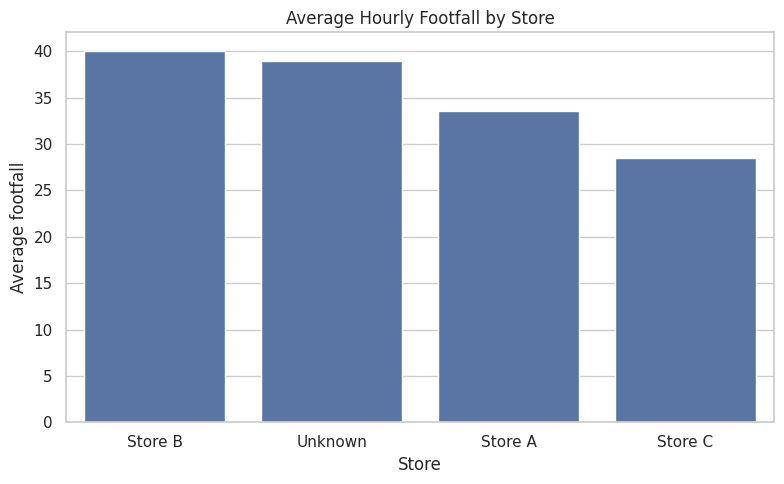

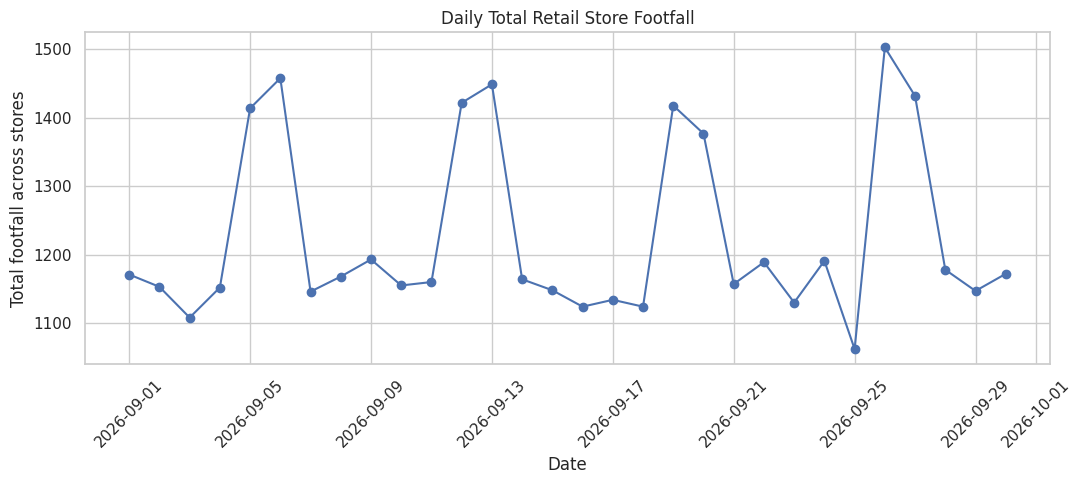

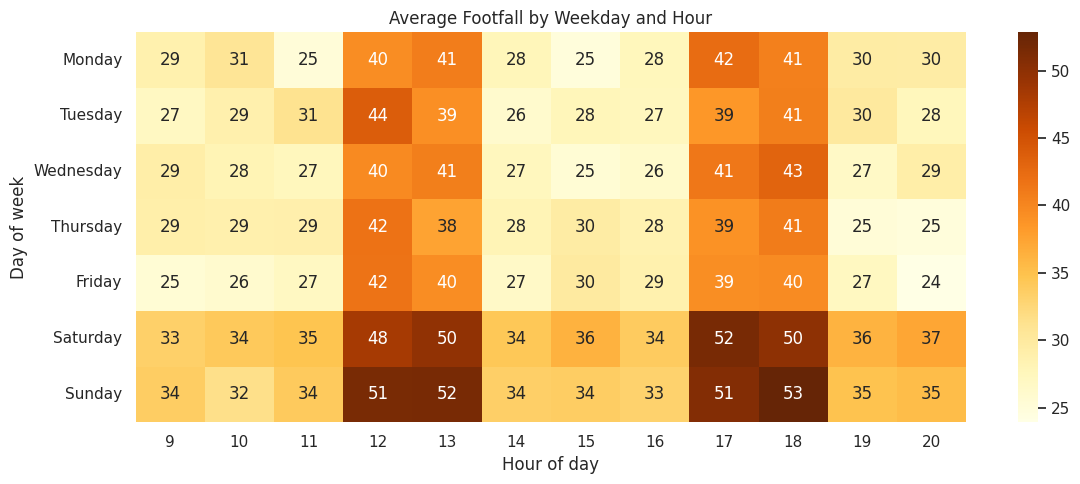

In [ ]:
# 1. Bar plot: average footfall by store
store_means = clean_df.groupby("Store")["Footfall"].mean().sort_values(ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(x=store_means.index, y=store_means.values)
plt.title("Average Hourly Footfall by Store")
plt.xlabel("Store")
plt.ylabel("Average footfall")
plt.tight_layout()
plt.show()

# 2. Line plot: total footfall by date
daily_totals = clean_df.groupby("Date")["Footfall"].sum().sort_index()
plt.figure(figsize=(11, 5))
plt.plot(daily_totals.index, daily_totals.values, marker="o")
plt.title("Daily Total Retail Store Footfall")
plt.xlabel("Date")
plt.ylabel("Total footfall across stores")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 3. Heatmap: average footfall by weekday and hour
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
heat_df = clean_df.copy()
heat_df["Weekday"] = heat_df["Date"].dt.day_name()
heat_pivot = heat_df.pivot_table(
    index="Weekday", columns="Hour", values="Footfall", aggfunc="mean"
).reindex(weekday_order)

plt.figure(figsize=(12, 5))
sns.heatmap(heat_pivot, annot=True, fmt=".0f", cmap="YlOrBr")
plt.title("Average Footfall by Weekday and Hour")
plt.xlabel("Hour of day")
plt.ylabel("Day of week")
plt.tight_layout()
plt.show()


**Conclusion/insight:** The bar plot compares average traffic across stores, the line plot shows how total traffic changes by date, and the heatmap highlights combinations of weekdays and hours with higher or lower average footfall. Use the actual charts produced by running the notebook to report specific findings.

## Overall conclusion
This project demonstrates how NumPy and Pandas can be used to summarize and clean retail footfall data, and how Matplotlib and Seaborn can communicate patterns visually. The analysis can help a retailer investigate busy hours, compare stores, and plan staffing or stock levels. However, the dataset is illustrative and does not represent real store activity. Real business decisions should be based on verified store records and additional context such as promotions, holidays, sales, and staffing.

